# Propensión de compra por visita

¿Qué visitas conviene atender primero cuando el equipo comercial tiene capacidad limitada? LightGBM puntúa cada visita antes de conocer su resultado. La variable objetivo, `incidencia_compra`, vale 1 cuando el cliente compra en la categoría observada y 0 cuando sale sin comprar.

Con la configuración presentada, el modelo obtuvo **ROC AUC de 0,714** en los días 621–730. Las 813 visitas de mayor puntaje reunieron **494 de las 2 050 compras**. Un piloto frente a la priorización habitual, con el mismo cupo, permitiría medir el efecto sobre el margen.

| Secciones | Recorrido |
|---|---|
| 1–3 · Datos | Calidad de las visitas, comportamiento de compra y selección de variables |
| 4–6 · Modelo | Ajuste temporal, evaluación del ordenamiento y contribuciones de cada variable |
| 7–8 · Resultados | Desempeño en test y ejemplo de priorización diaria |
| 9 · Uso comercial | Diseño del piloto y criterio para ampliar su uso |

Las celdas reproducen el análisis desde el CSV original, incluida la búsqueda de hiperparámetros.

## 1 · Configuración del entrenamiento

Optuna selecciona los parámetros que obtienen la menor **log loss** en las validaciones internas. El **ROC AUC** evalúa si el modelo ordena correctamente las visitas. Para emitir una decisión de compra o ausencia de compra, se escoge el umbral con mayor **F1** dentro del entrenamiento.

La búsqueda termina tras un mínimo de 50 pruebas completadas y 30 sin una mejora de al menos 0,0001. Los cortes por día se definen en `src/training.py`. Las variables se detallan en el [diccionario de predictores](../FEATURES.md).

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

# El progreso se imprime como texto y no requiere widgets de Jupyter.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=r"IProgress not found\.", module=r"tqdm\.auto$")
    import optuna

ROOT = Path.cwd() if (Path.cwd() / "Dataset").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src import eda, reporting, workflow
from src.data import audit, load_data
from src.feature_research import reviewed_features
from src.training import Config, compact_features

# Parada tras al menos 50 trials y 30 sin mejora relevante; sin máximo de trials.
config = Config(
    seed=42,
    minimum_trials=50,
    patience=30,
    minimum_improvement=0.0001,
    fold_workers=3,
    threads=4,
    stop_days=40,
    stopping_rounds=60,
    max_trees=2000,
)
DATA = ROOT / "Dataset/compras_data.csv"
OUTPUT = ROOT / "outputs" / os.environ.get("PROPENSION_RUN", "lightgbm")
optuna.logging.set_verbosity(optuna.logging.WARNING)
started = time.perf_counter()

## 2 · Datos y análisis exploratorio

Cada registro representa una visita. Un cliente puede aparecer en distintos días. La exploración utiliza **los días 1–296**, el primer período de entrenamiento.

Se comprueban la combinación cliente/día, la incidencia de compra, los precios y las promociones. La compra, la marca elegida y la cantidad de la visita actual se conocen después de la decisión. El historial incorpora esos datos una vez observados, para predecir visitas posteriores.

In [2]:
raw = load_data(DATA, end_day=620)
initial = raw.loc[raw.dia_visita.between(1, 296)].copy()
quality, semantics = audit(initial)
display(quality.rename("Valor").to_frame().T)
display(initial.head(3))

,filas,clientes,columnas,faltantes,duplicados,incoherencia_cantidad,incoherencia_marca
Valor,25754,500,24,0,0,0,0


,id,dia_visita,incidencia_compra,id_marca,cantidad,ultima_marca_comprada,ultima_cantidad_comprada,precio_marca_1,precio_marca_2,precio_marca_3,...,promo_marca_3,promo_marca_4,promo_marca_5,genero,estado_civil,edad,nivel_educacion,ingreso_anual,ocupacion,tamanio_ciudad
0,200000001,1,0,0,0,0,0,1.59,1.87,2.01,...,0,0,0,0,0,47,1,110866,1,0
1,200000001,11,0,0,0,0,0,1.51,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0
2,200000001,12,0,0,0,0,0,1.51,1.89,1.99,...,0,0,0,0,0,47,1,110866,1,0


### Cómo cambia la proporción de visitas con compra

Cada punto resume siete días desde la apertura, salvo el último tramo, que incluye dos. La conversión divide las compras entre las visitas del tramo. El volumen permite distinguir una variación extendida de otra observada en pocas visitas.

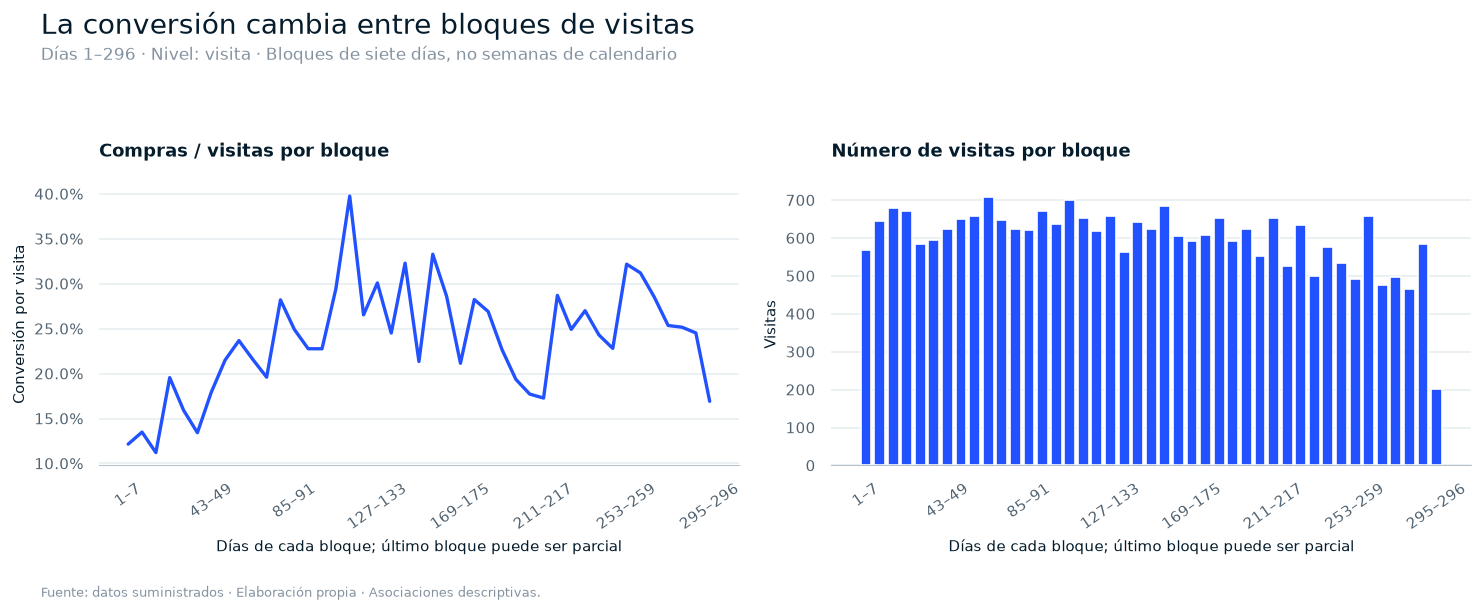

In [3]:
weekly_tables = reporting.show_eda(eda.weekly_plot(initial))

### La frecuencia y la conversión distinguen a los clientes
Nivel cliente · Cada persona se resume una vez en este período.

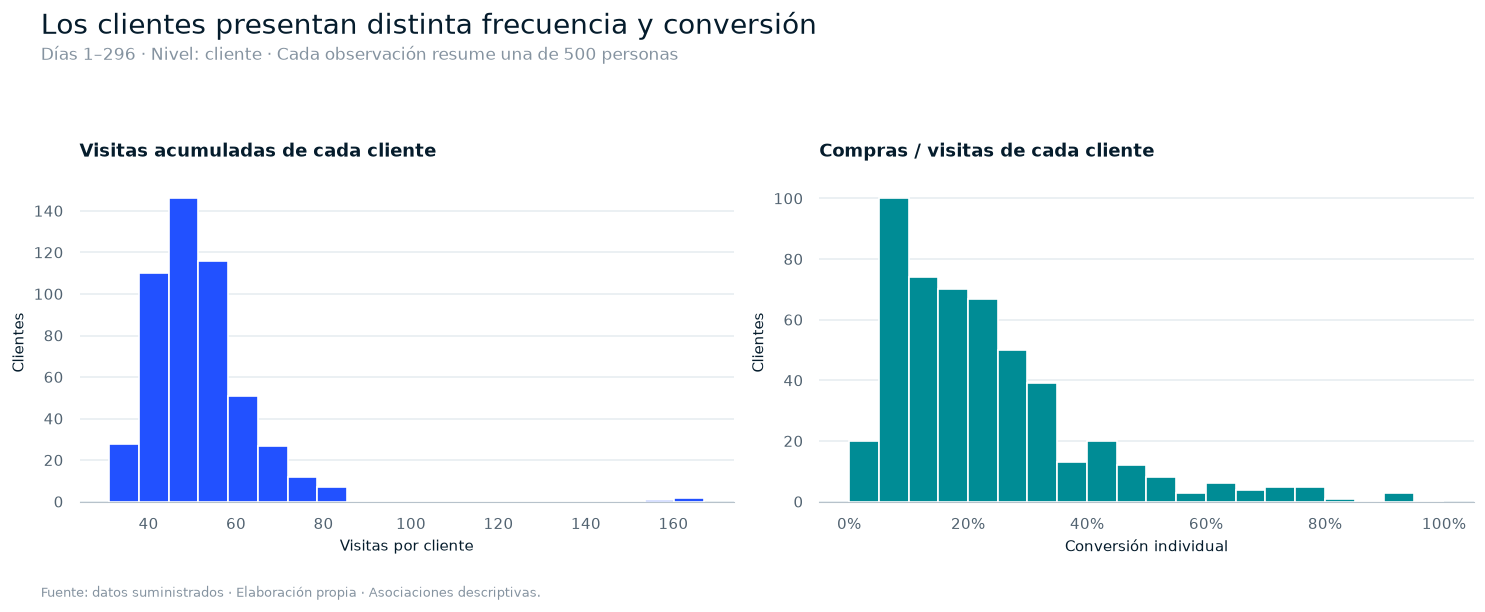

In [4]:
customer_tables = reporting.show_eda(eda.customer_plot(initial))

### Cuándo compró por última vez el cliente y cuántas veces visitó la tienda

Cada celda agrupa **visitas** según los días desde la última compra y el número de visitas anteriores del cliente. El primer gráfico muestra qué proporción terminó en compra. El segundo cuenta las visitas de cada combinación. Un mismo cliente puede cambiar de grupo conforme incorpora nuevas visitas.

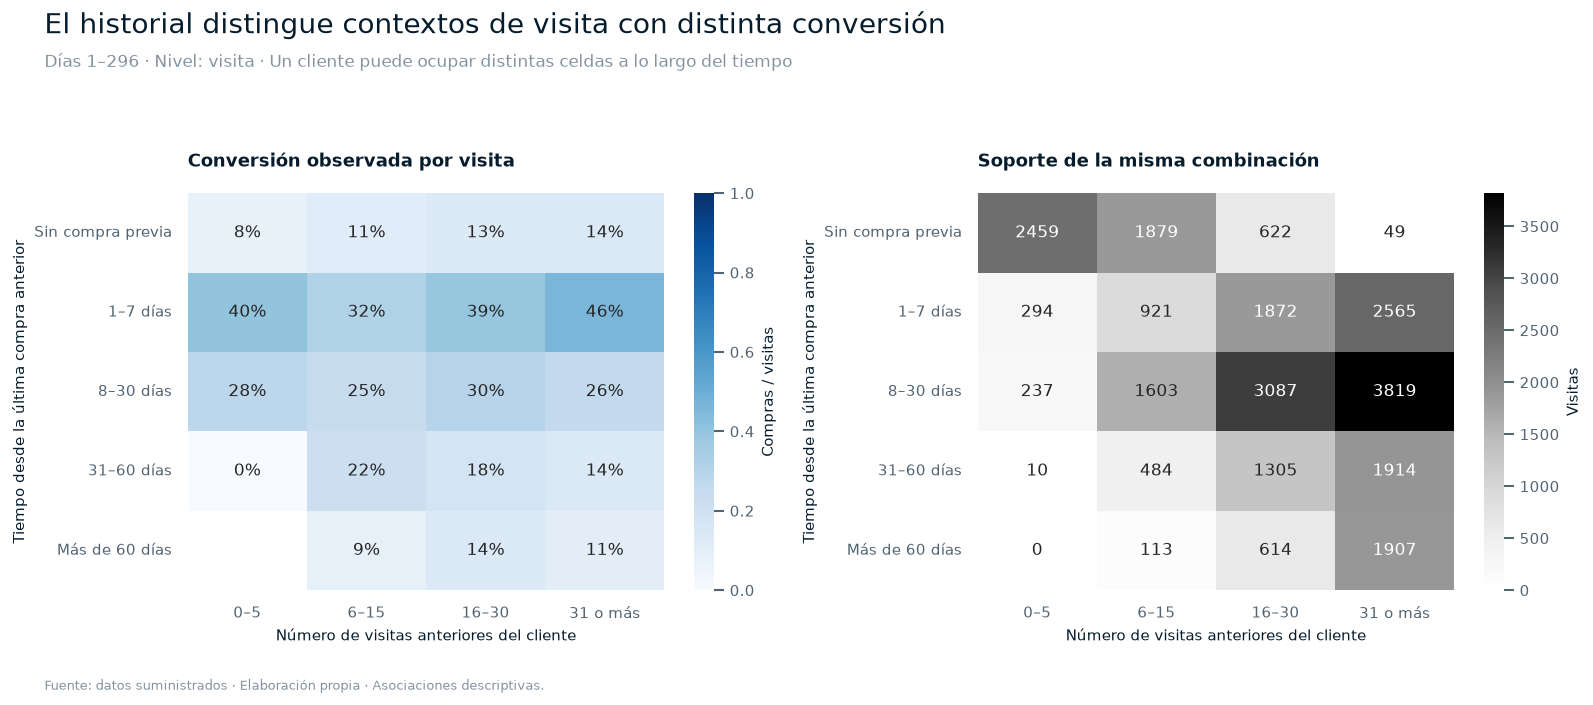

In [5]:
history_tables = reporting.show_eda(eda.history_plot(initial))

### Cómo varía la conversión según el perfil y las promociones

Se muestran las tasas y el número de observaciones que las sustentan. Como los clientes comparten las ofertas vigentes en un mismo día, las diferencias pueden reflejar también cambios en el tiempo.

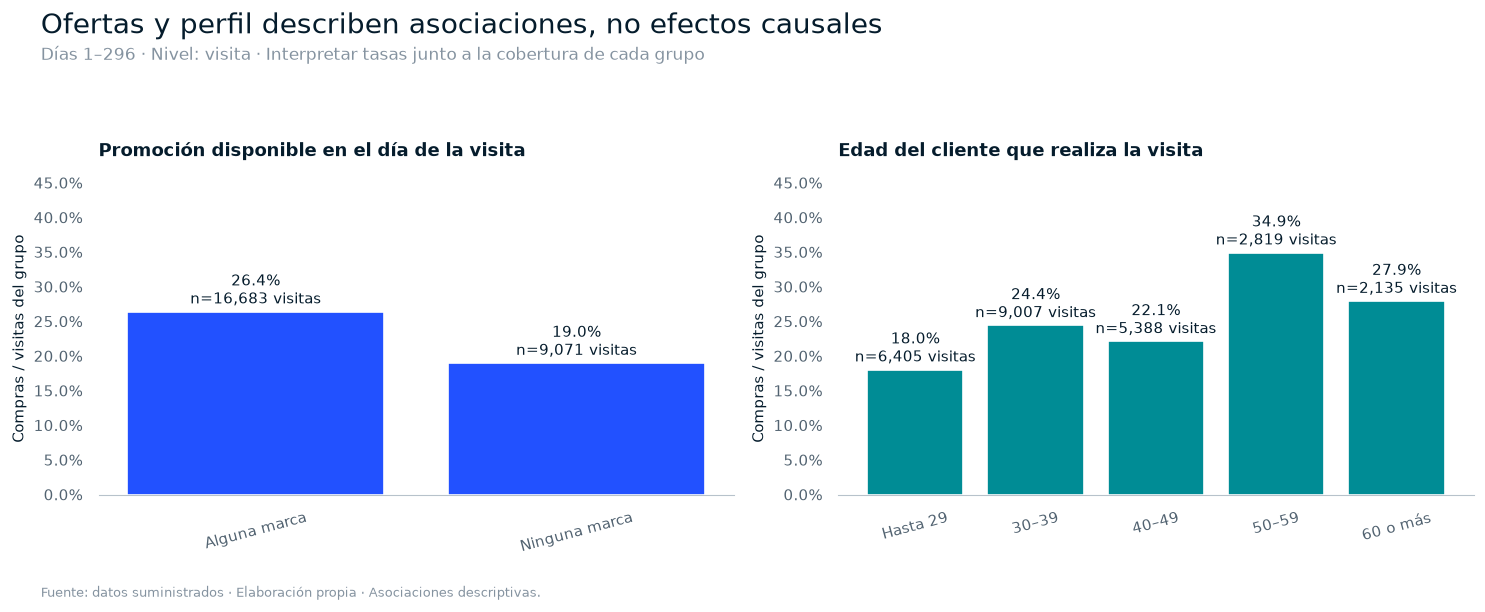

In [6]:
association_tables = reporting.show_eda(eda.association_plot(initial))

### Qué registran las columnas de última compra

En el período explorado, `ultima_marca_comprada` coincide con la marca registrada en la **visita anterior**. `ultima_cantidad_comprada` coincide con el indicador **compró o no compró en la visita anterior**. Se reconstruye la última compra efectiva a partir de las visitas en que sí hubo compra.

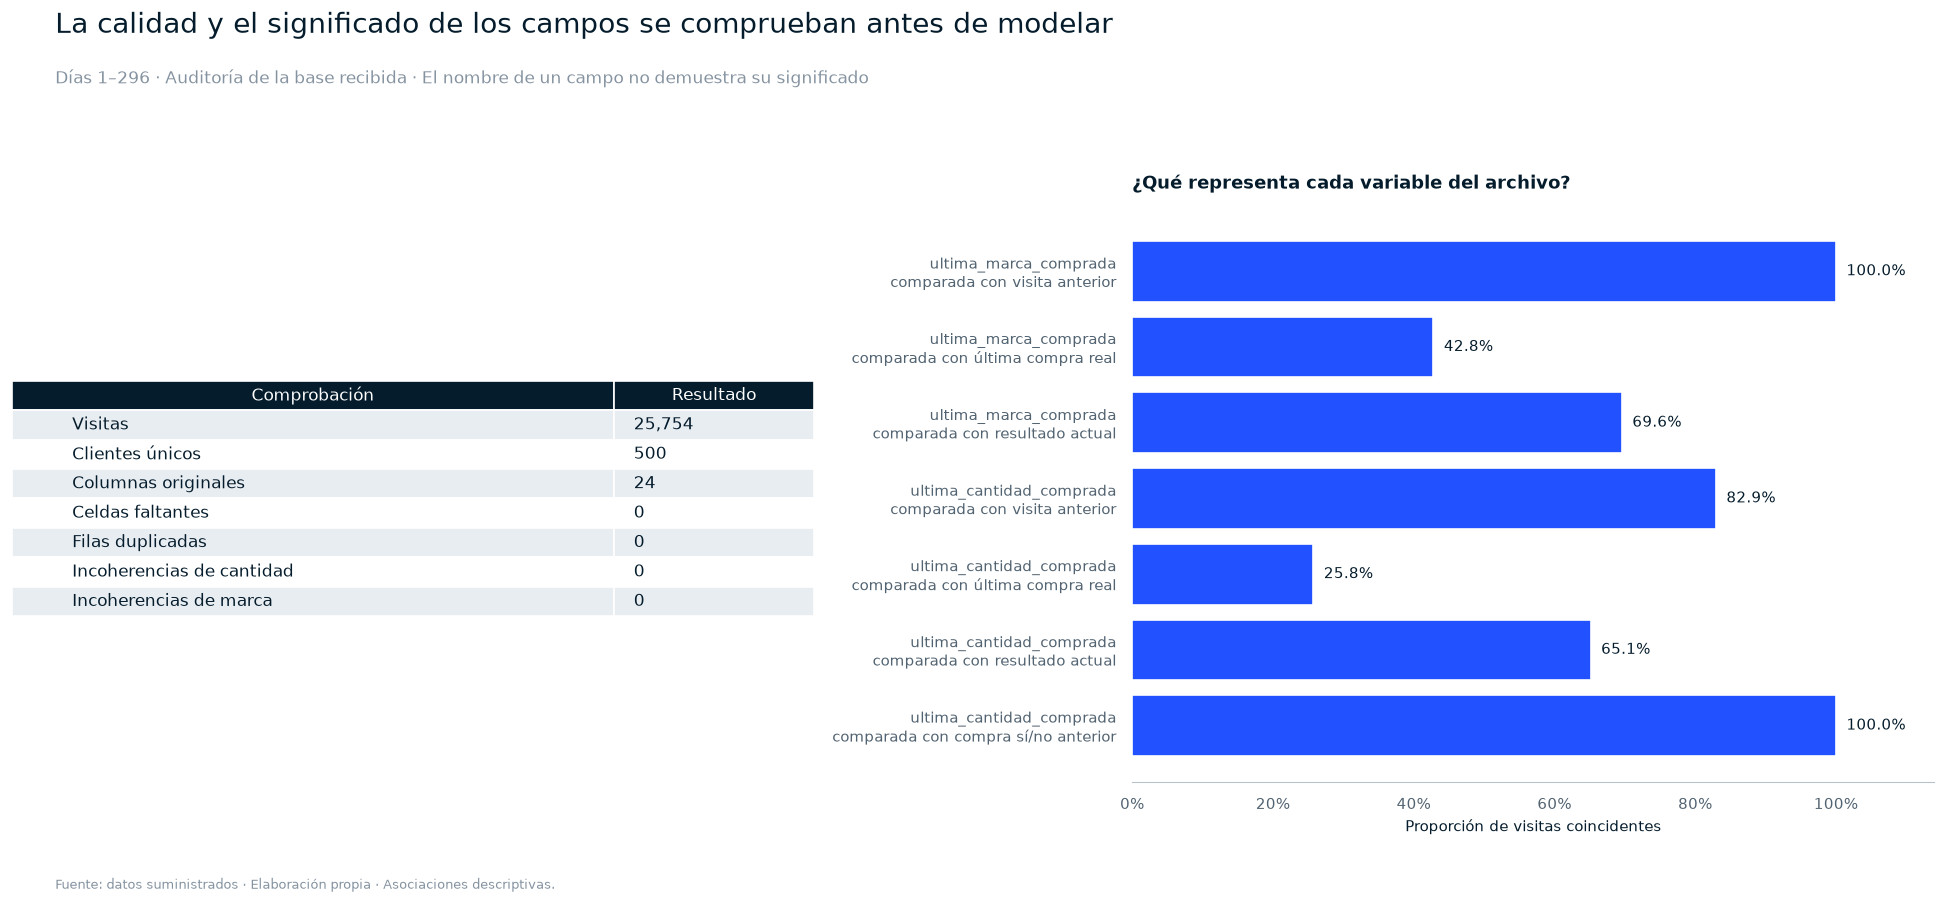

In [7]:
quality_tables = reporting.show_eda(eda.quality_plot(initial))

## 3 · De candidatos históricos a 17 predictores
Se reconstruyen recencia, frecuencia, tendencias y ofertas **anteriores al desenlace**. Los indicadores de tienda excluyen el día actual.

Un piloto con días 1–120 ordena los candidatos por SHAP; entre los 25 primeros elimina redundancia con |Spearman| ≥ 0,90. Quedan 17. La cantidad de variables se eligió comparando alternativas en desarrollo; por ello, estos folds describen el rendimiento del diseño seleccionado.

La imputación y codificación se aprenden dentro de cada train. Durante validación se actualiza el historial con visitas anteriores conocidas; el modelo permanece fijo.

In [8]:
events, candidates = reviewed_features(raw)
features, ranking = compact_features(events, candidates, config)
display(pd.DataFrame({"Predictores seleccionados": features.columns}))

,Predictores seleccionados
0,tasa_ultimas_10_visitas
1,precio_relativo_4
2,intervalo_compra_medio_previo
3,dias_desde_visita
4,month_recent_smoothed
5,unidades_por_dia_desde_compra
6,precio_relativo_1
7,month_visits_31_60
8,ingreso_anual
9,dias_desde_compra


### La correlación permite retirar señales redundantes
El gráfico usa únicamente días 1–120 y los 25 candidatos mejor clasificados por el piloto. Spearman mide asociación monotónica: valores cercanos a 1 en valor absoluto sugieren información repetida. El umbral 0,90 reduce redundancia; no demuestra causalidad ni significancia. Se conserva la variable mejor clasificada por SHAP.

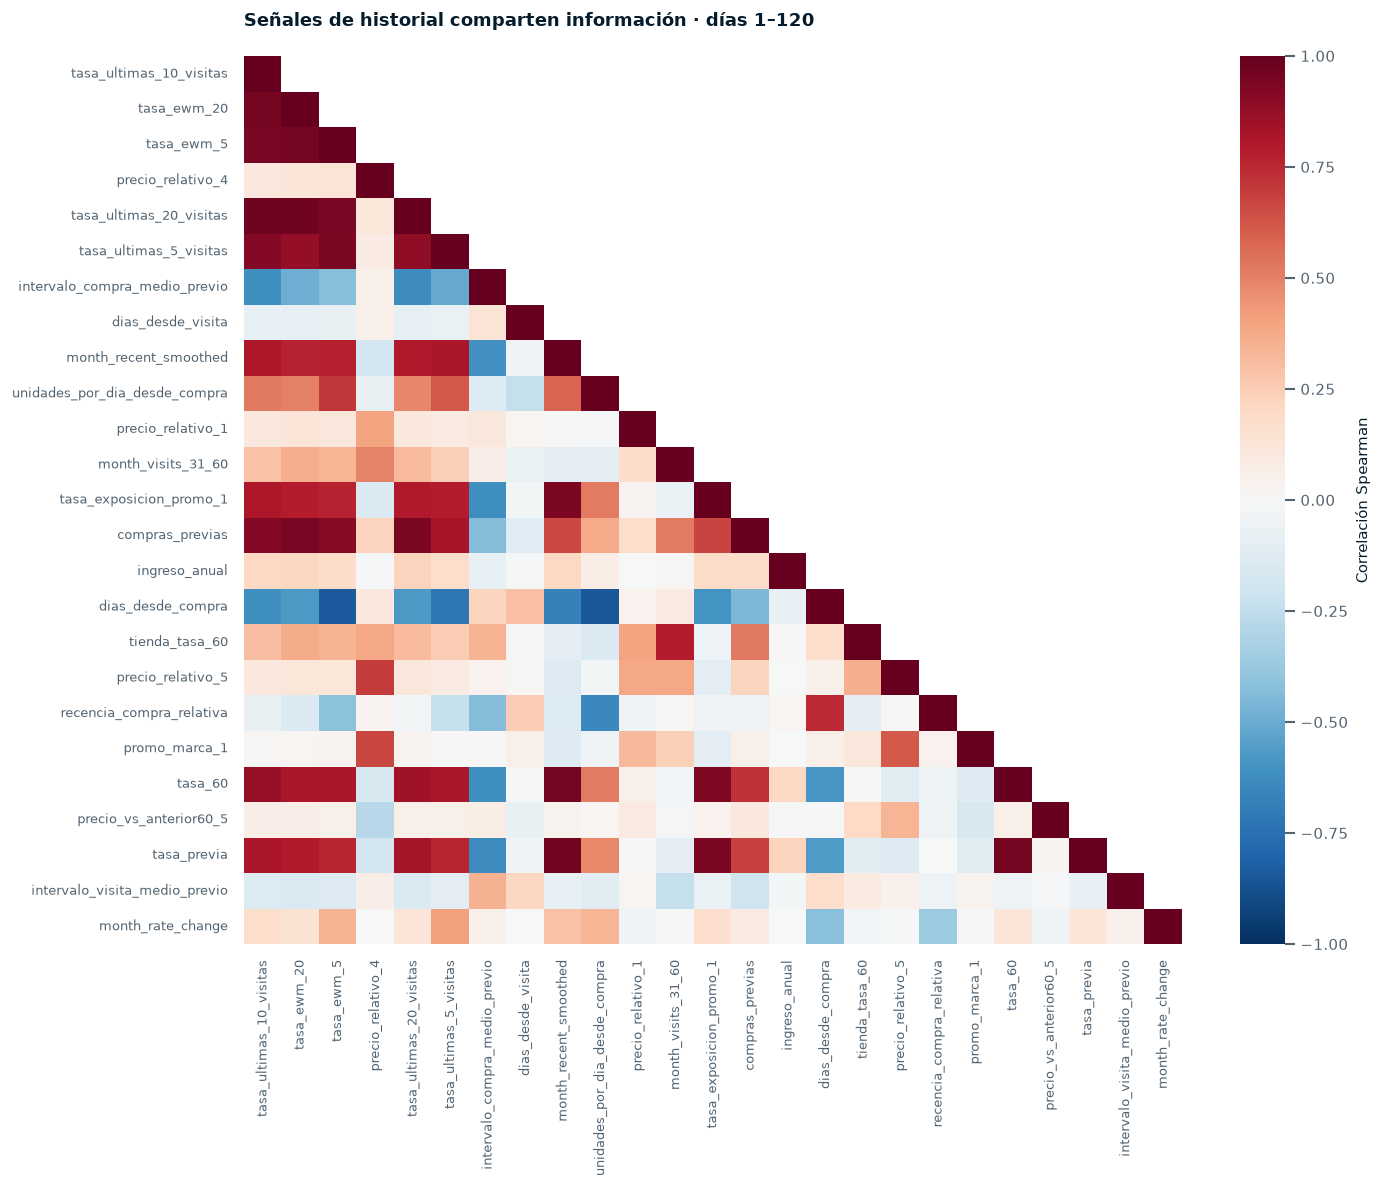

Variable A,Variable B,Spearman
tasa_ultimas_10_visitas,tasa_ultimas_20_visitas,0.973
tasa_ewm_20,tasa_ultimas_20_visitas,0.973
month_recent_smoothed,tasa_previa,0.968
tasa_60,tasa_previa,0.959
month_recent_smoothed,tasa_60,0.958
tasa_ewm_20,tasa_ewm_5,0.955
tasa_ultimas_10_visitas,tasa_ewm_20,0.954
tasa_ultimas_10_visitas,tasa_ewm_5,0.953


In [9]:
correlation_pairs = reporting.show_correlations(events, candidates, ranking)

## 4 · Entrenamiento y validación en tres períodos consecutivos

Cada corte amplía el historial de entrenamiento y evalúa las visitas del período siguiente. En cada búsqueda, los últimos 40 días de cada entrenamiento interno permiten elegir el número de árboles. El modelo se reajusta con ese entrenamiento completo y se evalúa en su validación interna. La validación exterior queda reservada para medir el resultado del corte.

In [10]:
reporting.show_protocol(events)
runs = {}

Fold,Train · días,Validación · días,Visitas train,Visitas validación,Validaciones internas · días
1,1–296,297–404,25754,8409,121–180; 181–238; 239–296
2,1–404,405–512,34163,8364,221–296; 297–350; 351–404
3,1–512,513–620,42527,8029,297–404; 405–458; 459–512


### Fold 1 · Entrenamiento 1–296 → Validación 297–404

In [11]:
runs[296] = workflow.run_fold(events, features, candidates, 296, 404, config)
reporting.show_search(runs[296])

Corte 296: 10 trials; mejor log loss 0.512068


Corte 296: 20 trials; mejor log loss 0.509099


Corte 296: 30 trials; mejor log loss 0.508793


Corte 296: 40 trials; mejor log loss 0.508793


Corte 296: 50 trials; mejor log loss 0.508793


**55 trials** · Log loss interna **0.5088** · Umbral **0.271** · 505 árboles · 13.7 s

Muestra,Visitas,ROC AUC,KS,Gini
Train,"25,754",0.747,0.363,49.4%
Validación,"8,409",0.723,0.334,44.5%


### Fold 2 · Entrenamiento 1–404 → Validación 405–512

In [12]:
runs[404] = workflow.run_fold(events, features, candidates, 404, 512, config)
reporting.show_search(runs[404])

Corte 404: 10 trials; mejor log loss 0.505264


Corte 404: 20 trials; mejor log loss 0.504204


Corte 404: 30 trials; mejor log loss 0.504204


Corte 404: 40 trials; mejor log loss 0.504204


Corte 404: 50 trials; mejor log loss 0.504141


**50 trials** · Log loss interna **0.5041** · Umbral **0.247** · 54 árboles · 16.8 s

Muestra,Visitas,ROC AUC,KS,Gini
Train,"34,163",0.756,0.376,51.1%
Validación,"8,364",0.773,0.401,54.6%


### Fold 3 · Entrenamiento 1–512 → Validación 513–620

In [13]:
runs[512] = workflow.run_fold(events, features, candidates, 512, 620, config)
reporting.show_search(runs[512])

Corte 512: 10 trials; mejor log loss 0.477785


Corte 512: 20 trials; mejor log loss 0.477450


Corte 512: 30 trials; mejor log loss 0.477168


Corte 512: 40 trials; mejor log loss 0.477105


Corte 512: 50 trials; mejor log loss 0.477105


Corte 512: 60 trials; mejor log loss 0.476416


Corte 512: 70 trials; mejor log loss 0.476416


Corte 512: 80 trials; mejor log loss 0.476416


**82 trials** · Log loss interna **0.4764** · Umbral **0.260** · 109 árboles · 42.7 s

Muestra,Visitas,ROC AUC,KS,Gini
Train,"42,527",0.783,0.419,56.6%
Validación,"8,029",0.748,0.376,49.6%


## 5 · Qué tan bien ordenan las visitas

**ROC AUC** es la métrica principal: mide con qué frecuencia se ordena una compra por encima de una no compra (un empate cuenta como medio acierto). **KS** es la máxima diferencia entre la proporción acumulada de compras y no compras. **Gini = 2 × AUC − 1** presenta el mismo ordenamiento global en otra escala. El promedio de validación da el mismo peso a cada fold.

En los **deciles**, LightGBM ordena de mayor a menor puntaje y divide las visitas en diez tramos por período. El desempate es reproducible e independiente del resultado. Se suman los conteos de deciles equivalentes entre folds, sin comparar puntajes de modelos entrenados en distintos cortes. La **conversión del decil** divide sus compras por sus visitas; las **compras acumuladas** dividen las compras capturadas hasta ese tramo por todas las compras del período. La diagonal del gráfico muestra la expectativa al azar; el tramo de atención depende de la capacidad comercial.

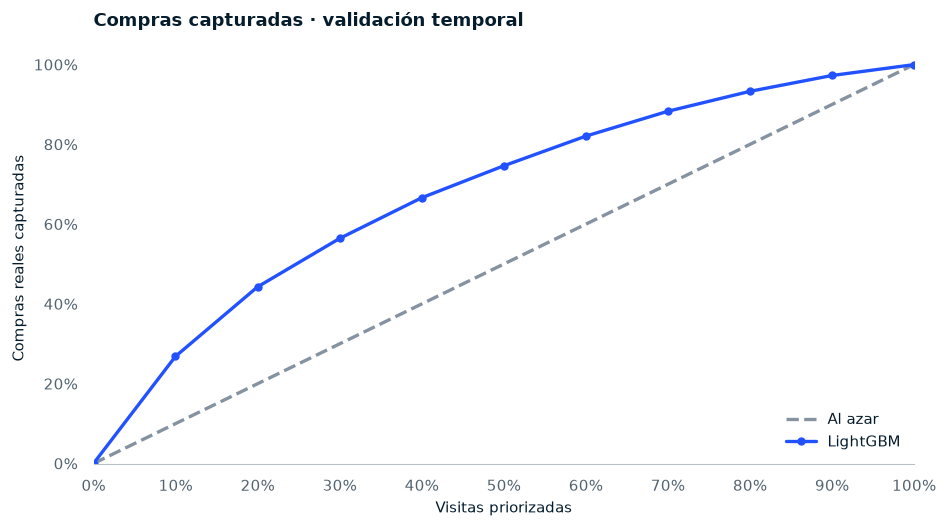

Decil,Visitas,Compras,Conversión,Compras capturadas
1,2478,1736,70.1%,26.9%
2,2480,1126,45.4%,44.3%
3,2481,785,31.6%,56.4%
4,2480,659,26.6%,66.6%
5,2481,518,20.9%,74.6%
6,2480,481,19.4%,82.1%
7,2480,403,16.2%,88.3%
8,2481,323,13.0%,93.3%
9,2480,257,10.4%,97.3%
10,2481,176,7.1%,100.0%


In [14]:
results = [row for run in runs.values() for row in run["metrics"]]
validation_deciles = [row for run in runs.values() for row in run["deciles"]]
reporting.show_deciles(validation_deciles, "Compras capturadas · validación temporal")

### Comparación histórica que orientó la elección del algoritmo

| Procedimiento | ROC AUC | Log loss ↓ |
|---|---:|---:|
| **LightGBM** | **0,756** | **0,483** |
| XGBoost | 0,756 | 0,484 |
| Ensamble temporal | 0,753 | 0,484 |
| CatBoost | 0,753 | 0,485 |
| Regresión logística | 0,749 | 0,487 |
| Red neuronal | 0,746 | 0,489 |
| Histórico acumulado | 0,724 | 0,499 |

**Elección:** LightGBM obtuvo prácticamente el mismo ROC AUC que XGBoost (0,75627 frente a 0,75642) y la menor log loss (0,4831 frente a 0,4841). Ese resultado motivó elegir LightGBM como familia.

[Fuente: investigación archivada](https://github.com/KireSregor/ferreyros-propension/blob/718c78cbea6d02ee91d504cf67e63852509ac9f0/outputs/review_v1/leaderboard.csv). Promedios de tres folds exteriores. Esta tabla describe configuraciones y presupuestos de búsqueda de la investigación; el modelo final de 17 variables tiene su propia evaluación en este notebook.

## 6 · Explicar qué señales usa LightGBM
Se muestran las **contribuciones SHAP de los 17 predictores** del modelo del tercer fold. Magnitud en log-odds: no indica causalidad ni, por sí sola, dirección del efecto.

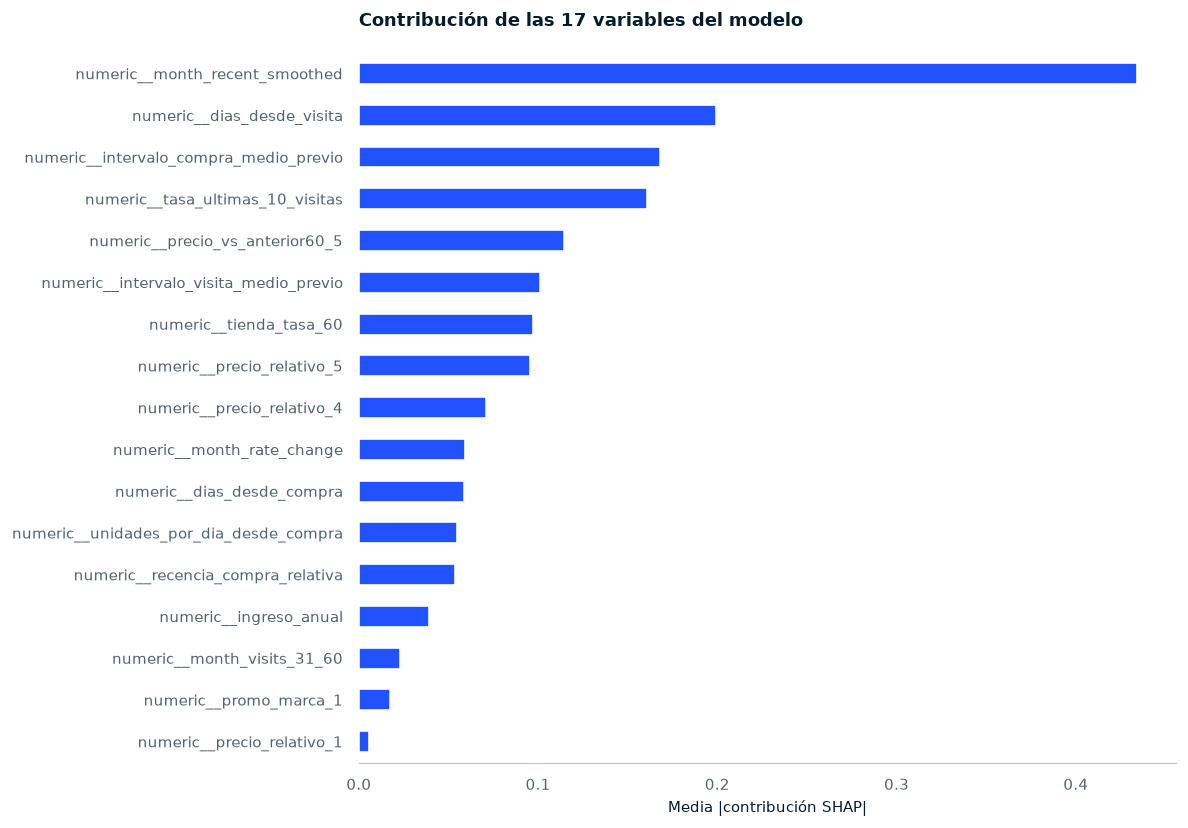

In [15]:
bundle = runs[512]["bundle"]
reporting.show_importance(bundle, features, events, config)

## 7 · Evaluación final en los días 621–730

El modelo entrenado hasta el día 512 se aplica a las 8 137 visitas de test con sus parámetros y su umbral fijos. Este período se consultó durante el desarrollo.

La primera tabla compara el ordenamiento de LightGBM con dos reglas. El **histórico acumulado** divide las compras previas más una entre las visitas previas más cuatro. La **tasa mensual suavizada** combina los últimos 30 días con los 90 anteriores. Las tres opciones usan las mismas visitas. Los valores de entrenamiento y validación son promedios simples de los tres cortes.

Para leer la decisión binaria, cada fila de la matriz indica lo que ocurrió y cada columna lo que predijo el modelo. Para leer los deciles, la **conversión** divide las compras de un grupo entre sus visitas y la **captura** divide las compras acumuladas hasta ese grupo entre todas las compras del test.

**Decisión por visita en test.** LightGBM predice compra cuando el puntaje alcanza el umbral de 26.0%.

,Predijo compra,Predijo ausencia de compra,Visitas
Resultado observado,,,
Compró,1122,928,2050
No compró,1437,4650,6087


Precisión,Recall,F1,Log loss
43.8%,54.7%,48.7%,0.507


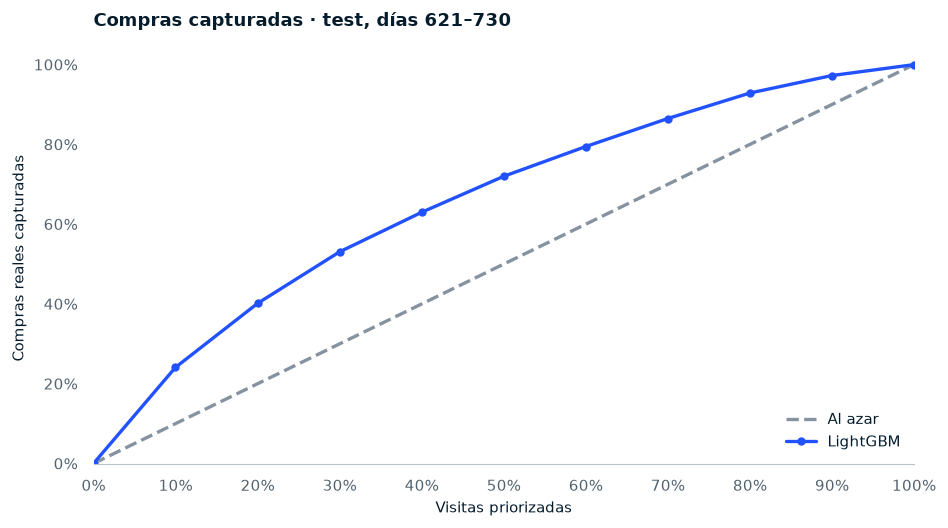

Decil,Visitas,Compras,Conversión,Compras capturadas
1,813,494,60.8%,24.1%
2,814,329,40.4%,40.1%
3,814,265,32.6%,53.1%
4,813,203,25.0%,63.0%
5,814,185,22.7%,72.0%
6,814,153,18.8%,79.5%
7,813,144,17.7%,86.5%
8,814,131,16.1%,92.9%
9,814,90,11.1%,97.3%
10,814,56,6.9%,100.0%


In [16]:
test_results, test_deciles = workflow.evaluate_test(runs[512], DATA, config)
results.extend(test_results)
reporting.show_results(pd.DataFrame(results))
reporting.show_final_results(pd.DataFrame(results), threshold=bundle["threshold"])
reporting.show_deciles(test_deciles, "Compras capturadas · test, días 621–730")

## 8 · Qué recibe el asesor antes de atender las visitas

La lista siguiente muestra las cinco visitas con mayor puntaje **del día 620**. Solo compiten por el cupo las visitas de ese día. En cambio, los deciles del test reúnen las visitas de **todo el período de 110 días**. La proporción de compras de un decil no determina cuántas se concentrarán en la cola diaria.

Se usan el historial hasta ayer, las ofertas vigentes y el perfil del cliente. El puntaje establece el orden de atención. Su calibración como probabilidad absoluta requeriría una verificación adicional. El resultado real se agrega a la tabla después de puntuar, para contrastarlo con la predicción.

In [17]:
scored = workflow.verify_scoring(
    bundle, raw, runs[512]["predictions"]["lightgbm_512_Validación"], events
)
reporting.show_predictions(scored, raw, bundle["threshold"])

**Primeras cinco visitas del día, por puntaje.** El umbral de 26.0% se usa para la decisión binaria.

Prioridad,Cliente,Día,Probabilidad estimada,Predicción,Resultado observado
1,200000187,620,92.9%,Compra,No compra
2,200000091,620,78.8%,Compra,Compra
3,200000297,620,78.8%,Compra,No compra
4,200000393,620,78.5%,Compra,No compra
5,200000422,620,64.6%,Compra,No compra


## 9 · Cómo probar el valor de priorizar con LightGBM

**Piloto propuesto:** asignar al azar clientes elegibles a priorización con LightGBM o a la práctica habitual. Mantener la misma acción, el mismo cupo y el mismo período de medición por grupo. La asignación por cliente evita que sus visitas pasen de un grupo al otro.

| Quién | Qué mide | Para qué |
|---|---|---|
| Analítica | Visitas puntuadas a tiempo; ROC AUC y KS con resultados observados | Detectar fallos de datos o pérdida de ordenamiento |
| Comercial | Gestiones ejecutadas sobre las planificadas; motivos de desvío | Separar problemas de adopción de problemas del modelo |
| Marketing | Diferencia de compras por cliente asignado | Medir el resultado comercial de la política |
| Finanzas | Diferencia de margen neto por cliente asignado | Decidir si conviene ampliar el uso |

Incluir a todos los clientes según su asignación, incluso si no fueron atendidos. Finanzas fija antes del piloto la mejora mínima que compensa el coste, con margen después de descuentos, gastos de contacto y operación. Dimensionar la muestra para ese objetivo. Escalar solo si el intervalo de confianza respalda la mejora mínima y se cumplen los límites acordados de capacidad y calidad de servicio.

Los deciles describen compras históricas concentradas por el modelo. El piloto es lo que permite atribuir compras o margen adicionales a la política de priorización.

### Guardar el modelo y los resultados
La ejecución guarda el estimador en `model.joblib`, las métricas por período en `metrics.csv`, los conteos por decil en `deciles.csv` y la configuración y los umbrales en `execution.json`.

In [18]:
trace = workflow.save_run(OUTPUT, runs, results, validation_deciles + test_deciles, config, DATA, started)
print(
    f"Ejecución completa: {trace['seconds'] / 60:.2f} min · Salidas: {OUTPUT.relative_to(ROOT)}"
)

Ejecución completa: 1.47 min · Salidas: outputs\lightgbm
